# Baselines, regresión logística y árbol de decisión


Se usa la partición creada en `01_EDA.ipynb` (`data/processed/particion.csv`).

## Configuración

Todos los modelos se comparan con validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento. El conjunto de prueba no se usa en este notebook.

In [2]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import make_scorer, precision_score, classification_report

sns.set_theme(style="whitegrid")
SEMILLA = 42

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_DATOS = RAIZ / "data" / "raw" / "diabetes_012_health_indicators_BRFSS2015.csv.zip"
RUTA_PARTICION = RAIZ / "data" / "processed" / "particion.csv"
DIR_RESULTADOS = RAIZ / "resultados"
DIR_RESULTADOS.mkdir(exist_ok=True)

OBJETIVO = "Diabetes_012"
NOMBRES_CLASE = {0: "Sin diabetes", 1: "Prediabetes", 2: "Diabetes"}

In [3]:
df = pd.read_csv(RUTA_DATOS).astype(int)
particion = pd.read_csv(RUTA_PARTICION, index_col="indice")["conjunto"]
train = df[particion == "train"]

X_train = train.drop(columns=OBJETIVO)
y_train = train[OBJETIVO]
print(f"X_train: {X_train.shape}")

X_train: (202944, 21)


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

METRICAS = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}

resultados = {}  # aquí se guardan las métricas de cada modelo


def metricas_mejor_modelo(busqueda):
    # Métricas promedio de validación cruzada del mejor modelo de un GridSearchCV
    i = busqueda.best_index_
    r = busqueda.cv_results_
    metricas = {m: r[f"mean_test_{m}"][i] for m in METRICAS}
    metricas["f1_macro_train"] = r["mean_train_f1_macro"][i]
    return metricas


def reporte_por_clase(modelo):
    # Precision, recall y F1 de cada clase usando predicciones de validación cruzada
    pred = cross_val_predict(modelo, X_train, y_train, cv=cv, n_jobs=-1)
    print(classification_report(y_train, pred, target_names=NOMBRES_CLASE.values(),
                                digits=3, zero_division=0))

## Baseline 

El modelo más simple posible: siempre predice la clase más frecuente ("sin diabetes"). Cualquier modelo útil debe superarlo.

In [5]:
dummy = DummyClassifier(strategy="most_frequent")
cv_dummy = cross_validate(dummy, X_train, y_train, cv=cv, scoring=METRICAS, return_train_score=True)

resultados["Baseline trivial"] = {m: cv_dummy[f"test_{m}"].mean() for m in METRICAS}
resultados["Baseline trivial"]["f1_macro_train"] = cv_dummy["train_f1_macro"].mean()
pd.Series(resultados["Baseline trivial"]).round(3)

accuracy           0.842
precision_macro    0.281
recall_macro       0.333
f1_macro           0.305
f1_macro_train     0.305
dtype: float64

**Resultado:** el baseline tiene 84% de accuracy, pero su F1 macro es solo 0.30.

**¿Por qué un accuracy alto no significa que el modelo sea bueno?** Como el 84% de las personas no tiene diabetes, un modelo que siempre responde "sin diabetes" acierta el 84% de las veces sin aprender nada. Sin embargo, no detecta a ninguna persona con prediabetes ni con diabetes, que son justamente los casos que nos interesan. El F1 macro sí lo refleja, porque promedia el desempeño de las tres clases por igual: el modelo obtiene un F1 de 0.91 en "sin diabetes" y 0 en las otras dos clases, y (0.91 + 0 + 0) / 3 ≈ 0.30.



## 4. Regresión logística

Buscamos el mejor valor de `C` (inverso de la regularización) y comprobamos si conviene usar pesos o no.

In [6]:
pipeline_logistica = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, solver="lbfgs")),
])

parametros_logistica = {
    "modelo__C": [0.01, 0.1, 1, 10],
    "modelo__class_weight": [None, "balanced"],
}

busqueda_logistica = GridSearchCV(pipeline_logistica, parametros_logistica, cv=cv,
                                  scoring=METRICAS, refit="f1_macro",
                                  return_train_score=True, n_jobs=-1)
busqueda_logistica.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_logistica.best_params_)
resultados["Regresión logística"] = metricas_mejor_modelo(busqueda_logistica)
pd.Series(resultados["Regresión logística"]).round(3)

Mejores hiperparámetros: {'modelo__C': 0.01, 'modelo__class_weight': 'balanced'}


accuracy           0.645
precision_macro    0.446
recall_macro       0.517
f1_macro           0.427
f1_macro_train     0.427
dtype: float64

In [7]:
# Resultados de todas las combinaciones probadas
tabla_logistica = pd.DataFrame(busqueda_logistica.cv_results_)[
    ["param_modelo__C", "param_modelo__class_weight", "mean_train_f1_macro", "mean_test_f1_macro"]]
tabla_logistica.columns = ["C", "class_weight", "F1 macro train", "F1 macro validación"]
tabla_logistica.sort_values("F1 macro validación", ascending=False).round(4)

,C,class_weight,F1 macro train,F1 macro validación
1,0.01,balanced,0.4274,0.4265
3,0.10,balanced,0.4273,0.4264
5,1.00,balanced,0.4273,0.4264
7,10.00,balanced,0.4273,0.4264
4,1.00,None,0.3936,0.3936
6,10.00,None,0.3936,0.3936
2,0.10,None,0.3936,0.3936
0,0.01,None,0.3934,0.3934


In [8]:
reporte_por_clase(busqueda_logistica.best_estimator_)

              precision    recall  f1-score   support

Sin diabetes      0.951     0.662     0.780    170962
 Prediabetes      0.030     0.299     0.054      3705
    Diabetes      0.357     0.590     0.445     28277

    accuracy                          0.645    202944
   macro avg      0.446     0.517     0.427    202944
weighted avg      0.851     0.645     0.720    202944



**Resultados:**
- Mejor configuración: **C = 0.01 con class_weight="balanced"**, con **F1 macro de 0.43**, mejor que el baseline trivial (0.30).
- Los pesos de clase sí ayudan: con balanced el F1 macro sube de 0.39 a 0.43. Sin pesos, el modelo casi nunca predice prediabetes.
- El valor de C casi no importa (todas las opciones dan alrededor de 0.426). Con más de 200 mil registros y solo 21 variables, el modelo tiene suficientes datos y la regularización tiene poco efecto.
- No hay sobreajuste: el F1 en entrenamiento (0.427) y en validación (0.426) son casi iguales.
- El accuracy baja a 65% porque, al dar más peso a las clases pequeñas, el modelo clasifica a más personas sanas como enfermas. Que es aceptable en un problema de este tipo, donde es preferible revisar de más que dejar pasar a alguien enfermo.
- La prediabetes sigue siendo el gran problema: el modelo encuentra al 30% de las personas con prediabetes, pero solo el 3% de las veces que predice "prediabetes" acierta (precision 0.03).

## Árbol de decisión

Los árboles no necesitan escalado, así que se entrenan directamente con los datos. Probamos 400 combinaciones de hiperparámetros:

- `max_depth`: profundidad máxima del árbol.
- `min_samples_split`: mínimo de registros para dividir un nodo.
- `min_samples_leaf`: mínimo de registros en cada hoja.
- `criterion`: medida de impureza (`gini` o `entropy`).
- `class_weight`: con o sin pesos para las clases.



In [9]:
arbol = DecisionTreeClassifier(class_weight="balanced", random_state=SEMILLA)

parametros_arbol = {
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 10, 25, 50],
    "min_samples_leaf": [1, 5, 10, 25, 50],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
}

busqueda_arbol = GridSearchCV(arbol, parametros_arbol, cv=cv, scoring=METRICAS,
                              refit="f1_macro", return_train_score=True, n_jobs=-1)
busqueda_arbol.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_arbol.best_params_)
mejor_arbol = busqueda_arbol.best_estimator_
print(f"Profundidad: {mejor_arbol.get_depth()}   Hojas: {mejor_arbol.get_n_leaves():,}")
resultados["Árbol de decisión"] = metricas_mejor_modelo(busqueda_arbol)
pd.Series(resultados["Árbol de decisión"]).round(3)

Mejores hiperparámetros: {'class_weight': None, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 25}
Profundidad: 33   Hojas: 11,547


accuracy           0.826
precision_macro    0.432
recall_macro       0.399
f1_macro           0.406
f1_macro_train     0.522
dtype: float64

In [10]:
# Las 5 mejores combinaciones
tabla_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
columnas = ["param_max_depth", "param_min_samples_split", "param_min_samples_leaf",
            "param_criterion", "param_class_weight", "mean_train_f1_macro", "mean_test_f1_macro"]
tabla_arbol.sort_values("mean_test_f1_macro", ascending=False)[columnas].head().round(4)

,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_criterion,param_class_weight,mean_train_f1_macro,mean_test_f1_macro
182,None,25,1,entropy,None,0.5218,0.4064
82,None,25,1,gini,None,0.5223,0.4063
186,None,25,5,entropy,None,0.4873,0.4060
86,None,25,5,gini,None,0.4839,0.4058
162,20,25,1,entropy,None,0.5112,0.4057


In [11]:
reporte_por_clase(busqueda_arbol.best_estimator_)

              precision    recall  f1-score   support

Sin diabetes      0.869     0.938     0.902    170962
 Prediabetes      0.030     0.004     0.006      3705
    Diabetes      0.398     0.255     0.311     28277

    accuracy                          0.826    202944
   macro avg      0.432     0.399     0.406    202944
weighted avg      0.788     0.826     0.804    202944



### Comparación con los baselines

In [12]:
comparacion = pd.DataFrame(resultados).T.round(3)
comparacion

,accuracy,precision_macro,recall_macro,f1_macro,f1_macro_train
Baseline trivial,0.842,0.281,0.333,0.305,0.305
Regresión logística,0.645,0.446,0.517,0.427,0.427
Árbol de decisión,0.826,0.432,0.399,0.406,0.522


- El árbol (F1 macro 0.41) supera al baseline trivial (0.30), pero no supera a la regresión logística (0.43).
- El mejor árbol no usa pesos de clase. Tiene el accuracy más alto de los modelos útiles (83%), pero casi nunca predice prediabetes: solo detecta el 0.4% de esos casos y el 25% de las personas con diabetes. Lo compensa con un F1 muy alto en "sin diabetes".
- Esto muestra una limitación de buscar solo con F1 macro: el árbol "ganador" sacrifica por completo la clase prediabetes.

In [13]:
balanceados = tabla_arbol[tabla_arbol["param_class_weight"] == "balanced"]
fila = balanceados.loc[balanceados["mean_test_f1_macro"].idxmax()]
print("Mejor árbol balanceado:", fila["params"])
print(f"F1 macro validación: {fila['mean_test_f1_macro']:.4f}\n")

reporte_por_clase(DecisionTreeClassifier(random_state=SEMILLA, **fila["params"]))

Mejor árbol balanceado: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
F1 macro validación: 0.4015

              precision    recall  f1-score   support

Sin diabetes      0.951     0.599     0.735    170962
 Prediabetes      0.027     0.291     0.049      3705
    Diabetes      0.320     0.616     0.421     28277

    accuracy                          0.596    202944
   macro avg      0.433     0.502     0.402    202944
weighted avg      0.846     0.596     0.679    202944



El mejor árbol balanceado tiene profundidad 5 y un F1 macro casi igual (0.40 frente a 0.41), pero detecta al 29% de las personas con prediabetes en lugar del 0.4%. Además es mucho más simple de interpretar. Si el grupo prioriza detectar casos de riesgo, este árbol es una mejor opción que el que eligió la búsqueda.

### Análisis de sobreajuste

Dejamos fijos los demás hiperparámetros del mejor árbol y comparamos el F1 macro en entrenamiento y en validación al cambiar solo la profundidad.

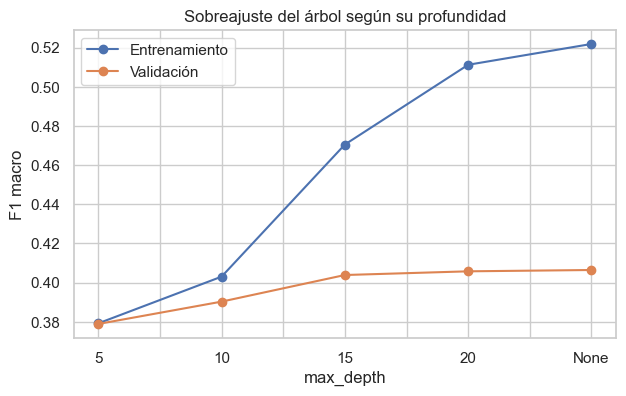

,mean_train_f1_macro,mean_test_f1_macro
param_max_depth,,
5,0.379,0.379
10,0.403,0.390
15,0.470,0.404
20,0.511,0.406
None,0.522,0.406


In [14]:
otros = {k: v for k, v in busqueda_arbol.best_params_.items() if k != "max_depth"}
mismo_resto = tabla_arbol["params"].apply(lambda p: all(p[k] == v for k, v in otros.items()))
por_profundidad = tabla_arbol[mismo_resto]
por_profundidad.index = por_profundidad["param_max_depth"].astype(str)

por_profundidad[["mean_train_f1_macro", "mean_test_f1_macro"]].plot(marker="o", figsize=(7, 4))
plt.legend(["Entrenamiento", "Validación"])
plt.xlabel("max_depth")
plt.ylabel("F1 macro")
plt.title("Sobreajuste del árbol según su profundidad")
plt.show()

por_profundidad[["mean_train_f1_macro", "mean_test_f1_macro"]].round(3)

Sí hay sobreajuste cuando el árbol crece mucho:
- Con profundidad 5, el F1 en entrenamiento y validación es igual (0.379): el árbol generaliza bien, aunque es algo simple.
- Al aumentar la profundidad, el F1 en entrenamiento sigue subiendo (hasta 0.52), pero el de validación se estanca en 0.41 a partir de profundidad 15. La diferencia entre ambos crece hasta 0.12: el árbol empieza a "memorizar" los datos de entrenamiento en lugar de aprender patrones generales.
- El mejor árbol de la búsqueda no tiene límite de profundidad: llega a profundidad 33 con más de 11 mil hojas. Lo que evita que se sobreajuste aún más es min_samples_split=25.
- Su ventaja sobre el árbol balanceado de profundidad 5 es mínima (0.406 frente a 0.402), así que un árbol poco profundo es mejor.

### Importancia de las variables

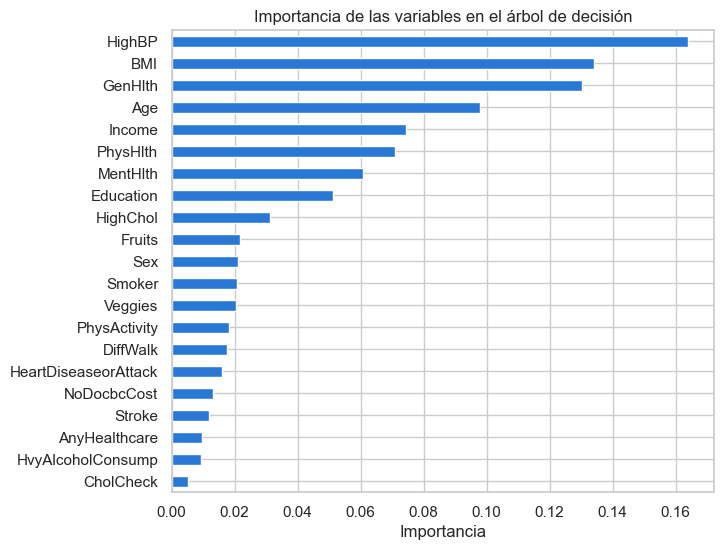

HighBP                  0.164
BMI                     0.134
GenHlth                 0.130
Age                     0.098
Income                  0.074
PhysHlth                0.071
MentHlth                0.061
Education               0.051
HighChol                0.031
Fruits                  0.022
Sex                     0.021
Smoker                  0.021
Veggies                 0.020
PhysActivity            0.018
DiffWalk                0.018
HeartDiseaseorAttack    0.016
NoDocbcCost             0.013
Stroke                  0.012
AnyHealthcare           0.010
HvyAlcoholConsump       0.009
CholCheck               0.005
dtype: float64

In [15]:
importancia = pd.Series(busqueda_arbol.best_estimator_.feature_importances_, index=X_train.columns)
importancia = importancia.sort_values()

importancia.plot.barh(figsize=(7, 6), color="#2a78d6")
plt.xlabel("Importancia")
plt.title("Importancia de las variables en el árbol de decisión")
plt.show()

importancia.sort_values(ascending=False).round(3)

- Las variables más importantes son presión alta (`HighBP`), IMC (`BMI`), salud general (`GenHlth`) y edad (`Age`), igual que en el análisis exploratorio.
- Después aparecen ingreso, días de mala salud física y mental, y educación.
- Variables como `CholCheck`, `HvyAlcoholConsump` y `AnyHealthcare` casi no se usan.
- `MentHlth` aparece más importante que en las correlaciones. Esto se debe en parte al sobreajuste: un árbol muy profundo usa variables con muchos valores distintos para separar casos individuales.

## Resultados finales

Se guardaron los hiperparámetros y la tabla de resultados en la carpeta resultados/ para las comparaciones

In [16]:
mejores_hiperparametros = {
    "regresion_logistica": busqueda_logistica.best_params_,
    "arbol_decision": busqueda_arbol.best_params_,
}
with open(DIR_RESULTADOS / "mejores_hiperparametros_integrante1.json", "w") as f:
    json.dump(mejores_hiperparametros, f, indent=2)

comparacion.to_csv(DIR_RESULTADOS / "resultados_integrante1.csv")

print(json.dumps(mejores_hiperparametros, indent=2))
comparacion

{
  "regresion_logistica": {
    "modelo__C": 0.01,
    "modelo__class_weight": "balanced"
  },
  "arbol_decision": {
    "class_weight": null,
    "criterion": "entropy",
    "max_depth": null,
    "min_samples_leaf": 1,
    "min_samples_split": 25
  }
}


,accuracy,precision_macro,recall_macro,f1_macro,f1_macro_train
Baseline trivial,0.842,0.281,0.333,0.305,0.305
Regresión logística,0.645,0.446,0.517,0.427,0.427
Árbol de decisión,0.826,0.432,0.399,0.406,0.522


**Hallazgos:**
1. El baseline trivial muestra que el accuracy engaña: 84% sin detectar a ningún enfermo (F1 macro 0.30).
2. La regresión logística con pesos balanceados es el mejor de los tres modelos (F1 macro 0.43), sin sobreajuste.
3. El árbol de decisión no supera a la regresión logística (0.41). Si crece sin límite se sobreajusta, y sin pesos de clase ignora la prediabetes.
4. La prediabetes es la clase más difícil para todos los modelos: se parece mucho a las otras dos clases y es solo el 1.8% de los datos.
5. Las variables más útiles son presión alta, IMC, salud general y edad.

